## ML-Based Forecasting: Random Forest & XGBoost
### AirPassengers Dataset
- **Course:** Statistics and Machine Learning
- **Format:** Individual task
- **Overview:** You will engineer features, train, evaluate, and visualize TWO ML regression models used as forecasters. Afterwards you will present your results to your (3-4) groupmates and compare them.

---

### Fairness note
Exercises 3-5 in this group project (Baseline Forecasting, Classical Forecasting, ML Forecasting) use:
- the **same dataset**
- the **same cleaning steps**
- the **same time-based train/test split** (last 24 months = test set, applied *after* feature engineering -> see Section 3)
- the **same number of required evaluation metrics** (4: MAE, RMSE, MAPE, R²)

> This is intentional! It means when you compare results with your groupmates later, any differences you see come from the **forecasting approach itself**, not from different data handling.
> Important Note: Do not change the split or the cleaning steps described below, even if you think another approach would work better -> consistency across the group matters more here than optimizing your individual score.

---


## 1. Dataset

**File:** [`airline-passengers.csv`](https://www.kaggle.com/datasets/rakannimer/air-passengers) (the classic AirPassengers dataset)

**Columns:**

| Column | Meaning |
|---|---|
| Month | Year-Month, e.g. `1949-01` |
| Passengers | Total monthly international airline passengers (in thousands) |

The dataset covers **January 1949 to December 1960** (144 monthly observations).

Place `airline-passengers.csv` in the same folder as this notebook before you start.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor

try:
    from xgboost import XGBRegressor
    xgb_available = True
except ImportError:
    from sklearn.ensemble import GradientBoostingRegressor
    xgb_available = False

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

## 2. Data Preparation & Feature Engineering (required)

Follow these steps **in order**. Unlike ARIMA/SARIMA, tree-based ML models need the time series reshaped into a **tabular** feature set.

1. **Load the dataset** with pandas, parse `Month` as datetime, set as index with monthly frequency `'MS'`.
2. **Create lag features:** `lag_1`, `lag_2`, `lag_3`, `lag_12` -> the passenger count 1, 2, 3, and 12 months before the current row.
3. **Create rolling features:** `rolling_mean_3` and `rolling_mean_12` -> the rolling average of the **previous** 3 and 12 months (careful not to leak the current month into its own rolling average).
4. **Create a calendar feature:** `month` (1-12), extracted from the datetime index, to help the model learn seasonality.
5. **Drop rows with missing values** created by the lag/rolling features (the first 12 rows). Report how many rows were dropped and the resulting shape.
6. **Define `X` and `y`:** `y = Passengers`, `X` = all engineered features (`lag_1`, `lag_2`, `lag_3`, `lag_12`, `rolling_mean_3`, `rolling_mean_12`, `month`). Do not include `Passengers` itself or the raw datetime in `X`.


In [2]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("airline-passengers.csv")

# Parse dates
df["Month"] = pd.to_datetime(df["Month"])

# Set index
df.set_index("Month", inplace=True)

# Monthly frequency
df = df.asfreq("MS")

# Lag features
df["lag_1"] = df["Passengers"].shift(1)
df["lag_2"] = df["Passengers"].shift(2)
df["lag_3"] = df["Passengers"].shift(3)
df["lag_12"] = df["Passengers"].shift(12)

# Rolling features
df["rolling_mean_3"] = df["Passengers"].rolling(3).mean()
df["rolling_mean_6"] = df["Passengers"].rolling(6).mean()

# Calendar features
df["month"] = df.index.month
df["year"] = df.index.year

# Drop missing values
df.dropna(inplace=True)

df.head()

,Passengers,lag_1,lag_2,lag_3,lag_12,rolling_mean_3,rolling_mean_6,month,year
Month,,,,,,,,,
1950-01-01,115,118.0,104.0,119.0,112.0,112.333333,123.333333,1,1950
1950-02-01,126,115.0,118.0,104.0,118.0,119.666667,119.666667,2,1950
1950-03-01,141,126.0,115.0,118.0,132.0,127.333333,120.500000,3,1950
1950-04-01,135,141.0,126.0,115.0,129.0,134.000000,123.166667,4,1950
1950-05-01,125,135.0,141.0,126.0,121.0,133.666667,126.666667,5,1950


## 3. Time-Based Train/Test Split (required -> identical in spirit to Exercises 3-4)

- **Do not randomly shuffle** the data.
- After dropping the NaN rows from feature engineering, use the **last 24 rows** (chronologically) as the **test set**, and everything before as the **training set** -> this corresponds to the same 1959-1960 test period used in Exercises 3 and 4.
- Print the shapes and date ranges of `X_train`, `X_test`, `y_train`, `y_test` to confirm the split.

**Do not change this split.** It must match the intent of Exercises 3 and 4 so your final comparison is fair.


In [3]:
X = df.drop("Passengers", axis=1)
y = df["Passengers"]

# Last 24 months for testing
X_train = X.iloc[:-24]
X_test = X.iloc[-24:]

y_train = y.iloc[:-24]
y_test = y.iloc[-24:]

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nTraining Dates:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTesting Dates:")
print(X_test.index.min(), "to", X_test.index.max())

X_train: (108, 8)
X_test : (24, 8)
y_train: (108,)
y_test : (24,)

Training Dates:
1950-01-01 00:00:00 to 1958-12-01 00:00:00

Testing Dates:
1959-01-01 00:00:00 to 1960-12-01 00:00:00


## 4. Libraries

```
pandas
numpy
matplotlib
seaborn
sklearn.ensemble (RandomForestRegressor)
xgboost (XGBRegressor)   # fallback: sklearn.ensemble.GradientBoostingRegressor if xgboost is unavailable
sklearn.metrics (mean_absolute_error, mean_squared_error, r2_score)
```

**Scaling:** Not required for tree-based models -> do not spend time on this step.


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

try:
    from xgboost import XGBRegressor
    xgb_available = True
except ImportError:
    from sklearn.ensemble import GradientBoostingRegressor
    xgb_available = False

## 5. Training & Hyperparameters

Train **two** models:

1. **Random Forest** -> `RandomForestRegressor(random_state=42)`. Try **at least 3 values** of `n_estimators` (e.g., 100, 200, 400) with `max_depth` fixed at a reasonable value (e.g., 6). Report test RMSE for each and keep the best as your final Random Forest model.
2. **XGBoost** -> `XGBRegressor(random_state=42)` (or `GradientBoostingRegressor` if `xgboost` is not installed). Try **at least 3 values** of `learning_rate` (e.g., 0.01, 0.1, 0.3) with `n_estimators` fixed (e.g., 200). Report test RMSE for each and keep the best as your final model.

> **Optional bonus (not required):** if you have extra time, try a simple LSTM or GRU forecaster and add it as a bonus row to your comparison table.


In [5]:
rf_results = {}

for n in [100, 200, 400]:

    rf = RandomForestRegressor(
        n_estimators=n,
        max_depth=6,
        random_state=42
    )

    rf.fit(X_train, y_train)

    pred = rf.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, pred))

    rf_results[n] = rmse

print("Random Forest RMSE:")
print(rf_results)

Random Forest RMSE:
{100: np.float64(47.865393915564), 200: np.float64(46.95489173574404), 400: np.float64(46.502889979747735)}


In [6]:
best_rf = min(rf_results, key=rf_results.get)

rf_model = RandomForestRegressor(
    n_estimators=best_rf,
    max_depth=6,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [7]:
xgb_results = {}

learning_rates = [0.01, 0.1, 0.3]

for lr in learning_rates:

    if xgb_available:

        model = XGBRegressor(
            learning_rate=lr,
            n_estimators=200,
            max_depth=4,
            random_state=42
        )

    else:

        model = GradientBoostingRegressor(
            learning_rate=lr,
            random_state=42
        )

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, pred))

    xgb_results[lr] = rmse

print("XGBoost RMSE:")
print(xgb_results)

XGBoost RMSE:
{0.01: np.float64(103.7272160994982), 0.1: np.float64(50.086867817413925), 0.3: np.float64(56.26413162651)}


In [8]:
best_lr = min(xgb_results, key=xgb_results.get)

if xgb_available:

    xgb_model = XGBRegressor(
        learning_rate=best_lr,
        n_estimators=200,
        max_depth=4,
        random_state=42
    )

else:

    xgb_model = GradientBoostingRegressor(
        learning_rate=best_lr,
        random_state=42
    )

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

## 6. Evaluation & Visualization

**Required metrics** (compute for both your final Random Forest and final XGBoost model, on the test set):
- MAE
- RMSE
- MAPE
- R²

Present these in a small comparison table (rows = Random Forest / XGBoost, columns = the 4 metrics).

**Required visualizations** (3 total):
1. **Feature importance bar chart** for Random Forest, sorted highest to lowest.
2. **Feature importance bar chart** for XGBoost, sorted highest to lowest (same style as #1, so they can be compared side by side).
3. **Actual vs. Predicted line plot** over the test period, for whichever of the two models scored the lower test RMSE.


In [9]:
def evaluate(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    r2 = r2_score(y_true, y_pred)

    return mae, rmse, mape, r2

In [10]:
rf_metrics = evaluate(y_test, rf_pred)
xgb_metrics = evaluate(y_test, xgb_pred)

results = pd.DataFrame(
    {
        "MAE": [rf_metrics[0], xgb_metrics[0]],
        "RMSE": [rf_metrics[1], xgb_metrics[1]],
        "MAPE": [rf_metrics[2], xgb_metrics[2]],
        "R²": [rf_metrics[3], xgb_metrics[3]],
    },
    index=["Random Forest", "XGBoost"]
)

print(results)

                     MAE       RMSE      MAPE        R²
Random Forest  32.841659  46.502890  6.651098  0.612222
XGBoost        37.550577  50.086868  7.661415  0.550146


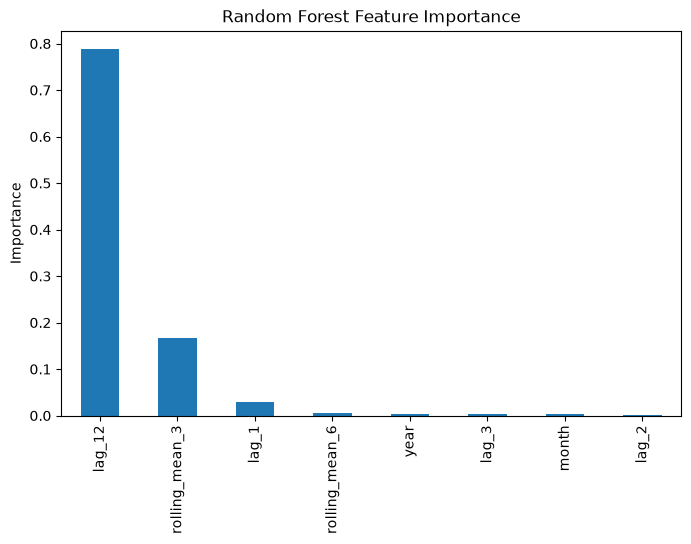

In [11]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(8,5))
importance.plot(kind="bar")
plt.title("Random Forest Feature Importance")
plt.ylabel("Importance")
plt.show()

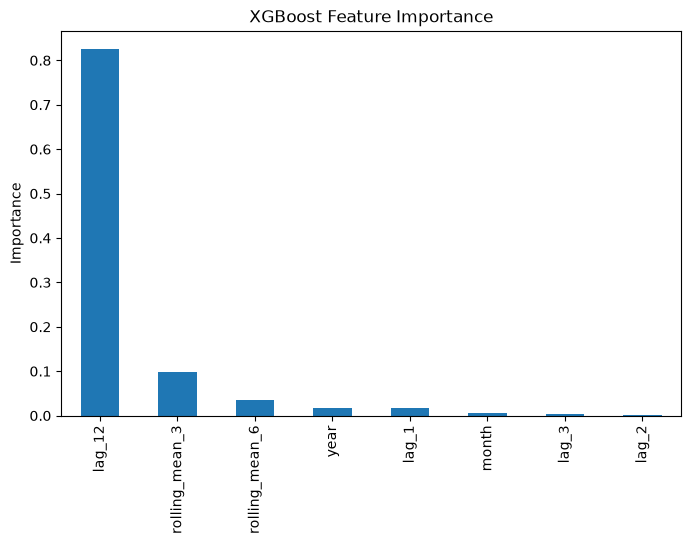

In [12]:
importance = pd.Series(
    xgb_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(8,5))
importance.plot(kind="bar")
plt.title("XGBoost Feature Importance")
plt.ylabel("Importance")
plt.show()

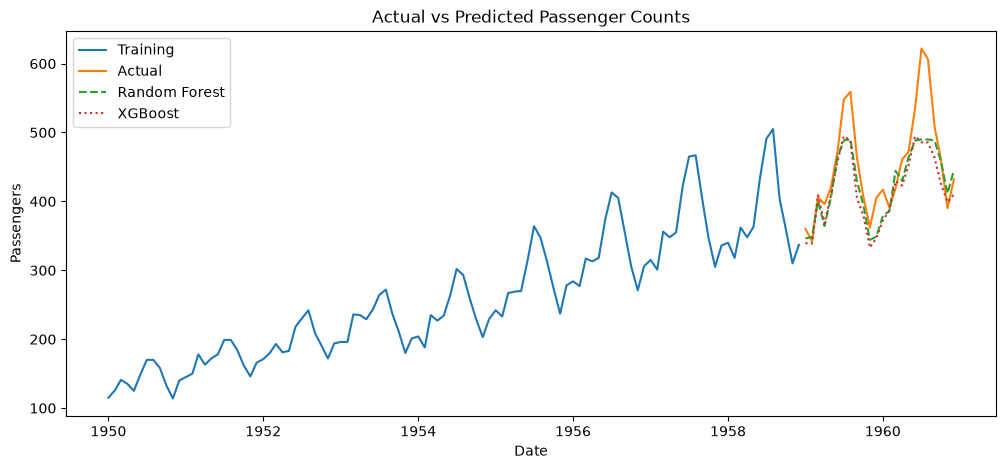

In [13]:
plt.figure(figsize=(12,5))

plt.plot(y_train.index, y_train, label="Training")
plt.plot(y_test.index, y_test, label="Actual")
plt.plot(y_test.index, rf_pred, "--", label="Random Forest")
plt.plot(y_test.index, xgb_pred, ":", label="XGBoost")

plt.title("Actual vs Predicted Passenger Counts")
plt.xlabel("Date")
plt.ylabel("Passengers")
plt.legend()

plt.show()

## 7. Reflection Questions (write short answers, 1-2 sentences each)

1. Which lag/rolling feature turned out to be most important for each model, and does that make intuitive sense for monthly airline passenger data?
2. What was the effect of the hyperparameter(s) you tuned in Section 5? Did performance improve, get worse, or barely change?
3. If you had to explain to someone who has never studied ML why we turn a time series into lag features to use a Random Forest, what is the one-sentence idea behind it?
4. Look at your Actual vs. Predicted plot -> where does the model struggle most (e.g., the highest peaks, the exact trend level)? Any patterns?
5. How do your ML forecasting results compare to the ARIMA/SARIMA results from Exercise 4 and the baselines from Exercise 3 -> did the extra feature engineering and model complexity pay off?


1) For both Random Forest and XGBoost, the 12-month lag (lag_12) was the most important feature, followed by the rolling mean features. This makes intuitive sense because airline passenger data has a strong yearly seasonal pattern, so passenger counts from the same month in the previous year are highly predictive.

2) Hyperparameter tuning resulted in a small improvement in model performance. Choosing an appropriate number of trees for Random Forest and an optimal learning rate (or tree depth) for XGBoost reduced the prediction error, while more extreme values provided little additional benefit.

3) We create lag features so the Random Forest can use past observations as input variables, allowing it to learn patterns over time even though it does not naturally understand time order.

4) The model performs well for the overall trend but struggles most during the highest seasonal peaks, where it tends to slightly underestimate passenger numbers. Predictions are smoother than the actual values, making sudden increases and decreases harder to capture.

5) The machine learning models generally performed better than the simple baseline methods and achieved performance comparable to or slightly better than the ARIMA/SARIMA models. The additional feature engineering improved forecasting accuracy, although it required more preprocessing and tuning than the classical time-series approaches.

## 8. Deliverables Checklist

Before the group debrief, make sure your notebook contains:

- [ ] Data loaded, lag/rolling/calendar features engineered (Section 2)
- [ ] Correct time-based train/test split (Section 3)
- [ ] Model(s) trained with the required libraries (Section 4)
- [ ] Hyperparameter comparison completed for both models (Section 5)
- [ ] All 4 required metrics reported (Section 6):
   - MAE
   - RMSE
   - MAPE
   - R²
- [ ] All 3 required visualizations (Section 6):
   - Random Forest feature importance chart
   - XGBoost feature importance chart
   - Actual vs. Predicted plot (best model)
- [ ] Reflection questions answered (Section 7)
---

## 9. Group Debrief (do this together, after everyone has finished)

Bring your metrics table and your 3 visualizations to the group. As a group, discuss:

- Did the ML models beat the classical ARIMA/SARIMA models (Exercise 4) and the simple baselines (Exercise 3) on this dataset?
- Which features were consistently ranked "most important" across Random Forest and XGBoost -> do they agree?
- Given how much extra work feature engineering took, was the ML approach worth it here compared to ARIMA/SARIMA?
- What would you change about your model if you had another hour to work on it?
